# Reservas de siniestros: Chain Ladder, Mack y bootstrap

Reserva del triángulo de Taylor y Ashe (1983) con Chain Ladder, su error estándar con Mack (1993) y su distribución con el bootstrap ODP de England y Verrall (2002). Los resultados publicados sirven para comprobar el código (ver `tests/`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from reserving import bootstrap_odp, chain_ladder, mack, to_incremental

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ACC, ORANGE = "#3E6470", "#D9822B"

## 1. Triángulo de desarrollo

In [2]:
tri_df = pd.read_csv(ROOT / "data" / "taylor_ashe_cumulative.csv", index_col=0)
tri = tri_df.to_numpy(float)
tri_df

,dev1,dev2,dev3,dev4,dev5,dev6,dev7,dev8,dev9,dev10
origin,,,,,,,,,,
1,357848,"1,124,788","1,735,330","2,218,270","2,745,596","3,319,994","3,466,336","3,606,286","3,833,515","3,901,463"
2,352118,"1,236,139","2,170,033","3,353,322","3,799,067","4,120,063","4,647,867","4,914,039","5,339,085",NaN
3,290507,"1,292,306","2,218,525","3,235,179","3,985,995","4,132,918","4,628,910","4,909,315",NaN,NaN
4,310608,"1,418,858","2,195,047","3,757,447","4,029,929","4,381,982","4,588,268",NaN,NaN,NaN
5,443160,"1,136,350","2,128,333","2,897,821","3,402,672","3,873,311",NaN,NaN,NaN,NaN
6,396132,"1,333,217","2,180,715","2,985,752","3,691,712",NaN,NaN,NaN,NaN,NaN
7,440832,"1,288,463","2,419,861","3,483,130",NaN,NaN,NaN,NaN,NaN,NaN
8,359480,"1,421,128","2,864,498",NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,376686,"1,363,294",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


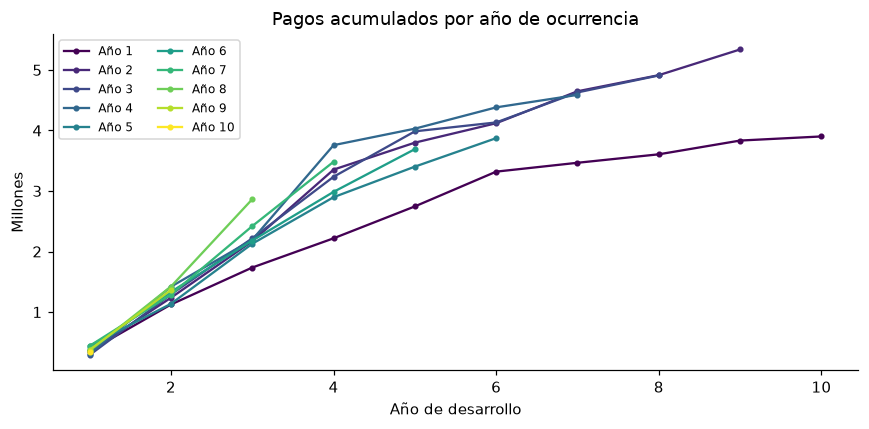

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
cmap = plt.get_cmap("viridis")
for i, row in enumerate(tri):
    ax.plot(range(1, 11), row / 1e6, marker="o", ms=3, color=cmap(i / 9), label=f"Año {i + 1}")
ax.set(title="Pagos acumulados por año de ocurrencia", xlabel="Año de desarrollo", ylabel="Millones")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "triangulo.png"); plt.show()

## 2. Chain Ladder

Factores de desarrollo ponderados por volumen, $\hat f_j = \sum_i C_{i,j+1} / \sum_i C_{i,j}$, y proyección
de cada año hasta su coste último.

In [4]:
cl = chain_ladder(tri)
pd.Series(cl.factors, index=[f"{j}-{j + 1}" for j in range(1, 10)], name="Factor").to_frame().T.style.format("{:.4f}")

,1-2,2-3,3-4,4-5,5-6,6-7,7-8,8-9,9-10
Factor,3.4906,1.7473,1.4574,1.1739,1.1038,1.0863,1.0539,1.0766,1.0177


In [5]:
cl.summary()

,Pagado,Último,Reserva (IBNR)
Año de ocurrencia,,,
1,"3,901,463","3,901,463",0
2,"5,339,085","5,433,719","94,634"
3,"4,909,315","5,378,826","469,511"
4,"4,588,268","5,297,906","709,638"
5,"3,873,311","4,858,200","984,889"
6,"3,691,712","5,111,171","1,419,459"
7,"3,483,130","5,660,771","2,177,641"
8,"2,864,498","6,784,799","3,920,301"
9,"1,363,294","5,642,266","4,278,972"


## 3. Modelo de Mack

Mack (1993) obtiene, sin suponer ninguna distribución, el error cuadrático medio de predicción de la reserva,
que combina el error de proceso (aleatoriedad de los pagos) y el error de estimación (de los factores).

In [6]:
mk = mack(tri)
summary = mk.summary()
summary.style.format({"Pagado": "{:,.0f}", "Último": "{:,.0f}", "Reserva (IBNR)": "{:,.0f}",
                      "Error estándar (Mack)": "{:,.0f}", "CV": "{:.1%}"}, na_rep="–")

,Pagado,Último,Reserva (IBNR),Error estándar (Mack),CV
Año de ocurrencia,,,,,
1,"3,901,463","3,901,463",0,0,–
2,"5,339,085","5,433,719","94,634","75,535",79.8%
3,"4,909,315","5,378,826","469,511","121,699",25.9%
4,"4,588,268","5,297,906","709,638","133,549",18.8%
5,"3,873,311","4,858,200","984,889","261,406",26.5%
6,"3,691,712","5,111,171","1,419,459","411,010",29.0%
7,"3,483,130","5,660,771","2,177,641","558,317",25.6%
8,"2,864,498","6,784,799","3,920,301","875,328",22.3%
9,"1,363,294","5,642,266","4,278,972","971,258",22.7%


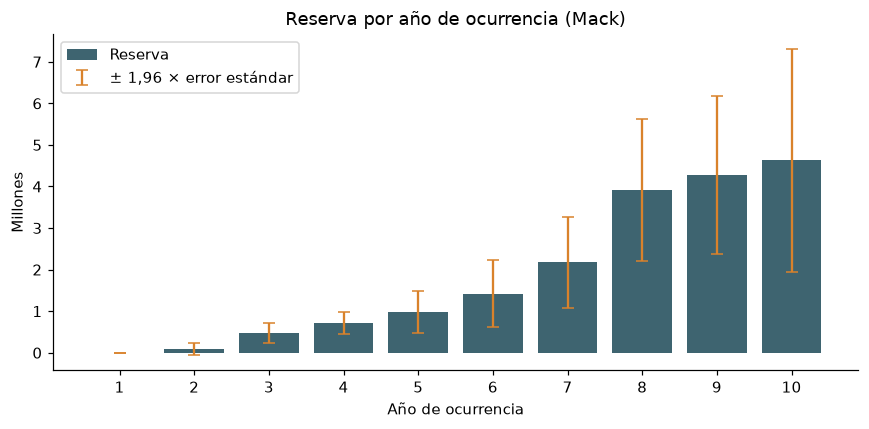

In [7]:
s = summary.drop("Total")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(s.index.astype(str), s["Reserva (IBNR)"] / 1e6, color=ACC, label="Reserva")
ax.errorbar(s.index.astype(str), s["Reserva (IBNR)"] / 1e6, yerr=1.96 * s["Error estándar (Mack)"] / 1e6,
            fmt="none", ecolor=ORANGE, capsize=4, label="± 1,96 × error estándar")
ax.set(title="Reserva por año de ocurrencia (Mack)", xlabel="Año de ocurrencia", ylabel="Millones")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "mack.png"); plt.show()

## 4. Bootstrap ODP

Siguiendo a England y Verrall (2002):
1. Se calculan los residuos de Pearson del modelo de Poisson sobredisperso equivalente a Chain Ladder.
2. Se remuestrean para crear 10.000 triángulos ficticios y se reestiman los factores (error de estimación).
3. Los pagos futuros se simulan con una Gamma de media $m$ y varianza $\phi\, m$ (error de proceso).

In [8]:
bs = bootstrap_odp(tri, n_sims=10_000, seed=2026)
print(f"Parámetro de dispersión φ: {bs.phi:,.0f}")
comparison = pd.DataFrame({
    "Media": [cl.reserve.sum(), bs.total.mean()],
    "Error estándar": [mk.se_total, bs.total.std()],
}, index=["Chain Ladder + Mack", "Bootstrap ODP"])
comparison["CV"] = comparison["Error estándar"] / comparison["Media"]
comparison.style.format({"Media": "{:,.0f}", "Error estándar": "{:,.0f}", "CV": "{:.1%}"})

Parámetro de dispersión φ: 52,601


,Media,Error estándar,CV
Chain Ladder + Mack,"18,680,856","2,447,095",13.1%
Bootstrap ODP,"18,925,133","3,026,028",16.0%


## 5. Percentiles y capital por riesgo de reservas

In [9]:
pct = bs.percentiles((0.5, 0.75, 0.9, 0.95, 0.99, 0.995))
best_estimate = bs.total.mean()
capital = pct["P99.5"] - best_estimate
print(f"Mejor estimación (media):            {best_estimate:,.0f}")
print(f"Percentil 99,5 %:                     {pct['P99.5']:,.0f}")
print(f"Capital (P99,5 − media), visión a último: {capital:,.0f}  ({capital / best_estimate:.1%} de la reserva)")
pct.to_frame("Reserva total")

Mejor estimación (media):            18,925,133
Percentil 99,5 %:                     28,030,167
Capital (P99,5 − media), visión a último: 9,105,033  (48.1% de la reserva)


,Reserva total
P50,"18,689,612"
P75,"20,850,941"
P90,"22,845,659"
P95,"24,152,580"
P99,"27,115,418"
P99.5,"28,030,167"


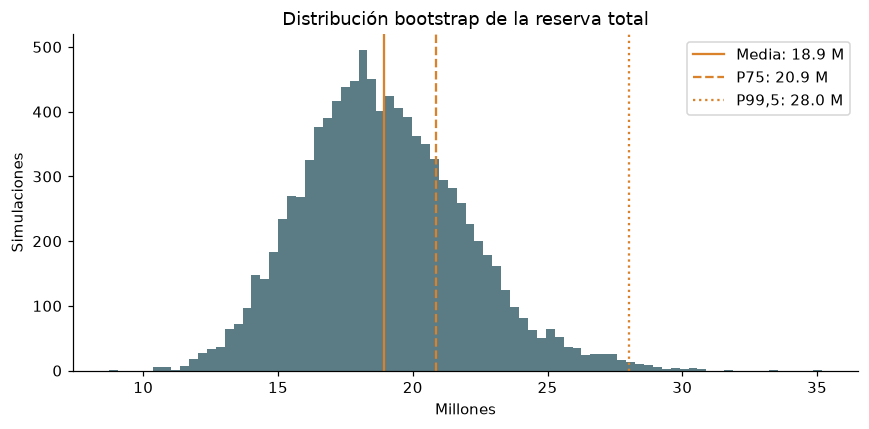

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(bs.total / 1e6, bins=80, color=ACC, alpha=0.85)
for label, val, ls in [("Media", best_estimate, "-"), ("P75", pct["P75"], "--"), ("P99,5", pct["P99.5"], ":")]:
    ax.axvline(val / 1e6, color=ORANGE, ls=ls, label=f"{label}: {val / 1e6:,.1f} M")
ax.set(title="Distribución bootstrap de la reserva total", xlabel="Millones", ylabel="Simulaciones")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "bootstrap.png"); plt.show()

> Nota. Solvencia II mide el riesgo de reservas a un año (cuánto puede empeorar la mejor estimación en los
> próximos 12 meses), mientras que este bootstrap da la visión a último (toda la vida de los siniestros).
> La visión a último es una cota superior útil y el punto de partida de los métodos a un año, como Merz-Wüthrich (2008).